<a href="https://colab.research.google.com/github/Raquelsantosb/analise-dados-python/blob/main/Python_em_CienciadeDados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Casos previstos para 2018 -> 330


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


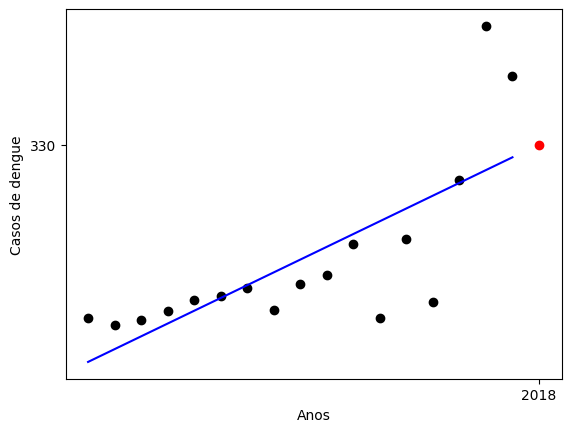

In [12]:
### SUPERVISIONADO - REGRESSÃO LINEAR ###


import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import pandas

#############      Pré-processamento     ###############
# Coleta e Integração
arquivo = pandas.read_csv('dados_dengue.csv')

anos = arquivo[['ano']]
casos = arquivo[['casos']]

##############       Mineração        #################
regr = LinearRegression()
regr.fit(X=anos, y=casos)

ano_futuro = [[2018]]
casos_2018 = regr.predict(ano_futuro)

print('Casos previstos para 2018 ->', int(casos_2018[0][0]))

############      Pós-processamento     ################
plt.scatter(anos, casos, color='black')
plt.scatter(ano_futuro, casos_2018, color='red')
plt.plot(anos, regr.predict(anos), color='blue')

plt.xlabel('Anos')
plt.ylabel('Casos de dengue')
plt.xticks([2018])
plt.yticks([int(casos_2018[0][0])])

plt.show()

In [14]:
###  SUPERVISIONADO - CLASSIFICAÇÃO  ###


from sklearn.datasets import load_iris, fetch_kddcup99
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.svm import SVC

##################      Pré-processamento     ###################
# Coleta e Integração
iris = load_iris()

caracteristicas = iris.data
rotulos = iris.target

print("Caracteristicas:\n", caracteristicas[:2])
print("Rótulos:\n", rotulos[:2])
print('########################################################')

# Partição dos dados
carac_treino, carac_teste, rot_treino, rot_teste = train_test_split(caracteristicas, rotulos)

###################       Mineração        #####################

############---------- Arvore de Decisão -----------############
arvore = DecisionTreeClassifier(max_depth=2)
arvore.fit(X=carac_treino, y=rot_treino)

rot_preditos = arvore.predict(carac_teste)
acuracia_arvore = accuracy_score(rot_teste, rot_preditos)
############-------- Máquina de Vetor Suporte ------############
clf = SVC()
clf.fit(X=carac_treino, y=rot_treino)

rot_preditos_svm = clf.predict(carac_teste)
acuracia_svm = accuracy_score(rot_teste, rot_preditos_svm)

################      Pós-processamento     ####################
print("Acurácia Árvore de Decisão:", round(acuracia_arvore, 5))
print("Acurácia SVM:", round(acuracia_svm, 5))
print('########################################################')

r = export_text(arvore, feature_names=iris['feature_names'])
print("Estrutura da árvore")
print(r)

Caracteristicas:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]]
Rótulos:
 [0 0]
########################################################
Acurácia Árvore de Decisão: 0.92105
Acurácia SVM: 0.97368
########################################################
Estrutura da árvore
|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal width (cm) <= 1.65
|   |   |--- class: 1
|   |--- petal width (cm) >  1.65
|   |   |--- class: 2



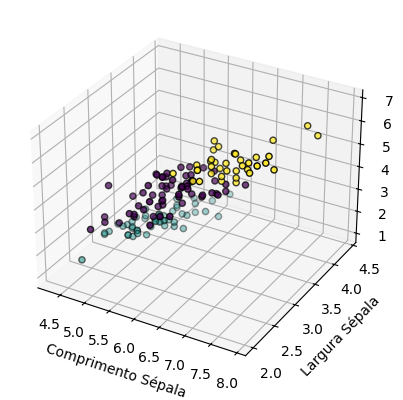

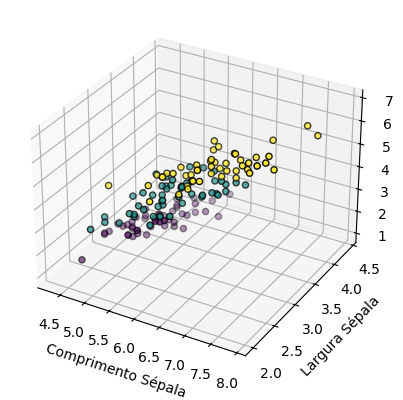

In [18]:
### NÃO SUPERVISIONADO - AGRUPAMENTO ###

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris

##################      Pré-processamento     ###################
# Coleta e Integração
iris = load_iris()

caracteristicas = iris.data

###################       Mineração        #####################
grupos = KMeans(n_clusters=3)
grupos.fit(X=caracteristicas)
labels = grupos.labels_    # indice do grupo ao qual cada amostra pertence

################      Pós-processamento     ####################
fig = plt.figure(1)
ax = fig.add_subplot(projection='3d')
ax.set_xlabel('Comprimento Sépala')
ax.set_ylabel('Largura Sépala')
ax.set_zlabel('Comprimento Pétala')
ax.scatter(caracteristicas[:, 0], caracteristicas[:, 1], caracteristicas[:, 2], c=grupos.labels_, edgecolor='k')

target = iris.target
fig = plt.figure(2)
ax = fig.add_subplot(projection='3d')
ax.set_xlabel('Comprimento Sépala')
ax.set_ylabel('Largura Sépala')
ax.set_zlabel('Comprimento Pétala')
ax.scatter(caracteristicas[:, 0], caracteristicas[:, 1], caracteristicas[:, 2], c=target, edgecolor='k')

plt.show()